# Zadanie 3: własny agent kodujący

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/adrianstando/2026Z-PJATK-TEG/blob/main/03-agenci/zadanie.ipynb)

**Oddanie:** mail z tematem `[TEG] lab-03`, w załączniku ten notebook **z wynikami komórek**, bez kluczy API.

**Termin:** przed zajęciami 4.

Agent kodujący to harness wokół modelu: pętla, narzędzia do plików i poleceń, historia. W tym zadaniu powstaje najprostsza wersja takiego harnessu w LangGraph, a agent dostaje jedno polecenie: zbudować małą aplikację z testami.

Części:
1. Narzędzia do pracy z plikami i uruchamiania poleceń.
2. Agent jako graf w LangGraph.
3. Uruchomienie agenta na podanym poleceniu i sprawdzenie wyniku.

Kod z [notebooka z zajęć](notebook.ipynb) można kopiować i modyfikować.

> **Uwaga.** Model sam układa polecenia, które wykona komputer. Najbezpieczniej uruchamiać notebook w Colabie albo Codespaces. Na własnym komputerze wszystkie pliki muszą powstawać w katalogu `workspace`, a polecenia wymagają zatwierdzenia przez człowieka albo sprawdzenia, czy nie wychodzą poza ten katalog.

## 0. Konfiguracja

Dostawcę wybiera się zmienną `LLM_PROVIDER`, tak jak w notebooku z zajęć ([00-dostep-do-llm](../00-dostep-do-llm/README.md)). Zadanie nie wymaga embeddingów. Agent wysyła dużo wywołań, więc dobrze sprawdza się mały i tani model z tool callingiem. Małe modele lokalne często mylą argumenty narzędzi.

In [28]:
import os

try:  # Colab: sekrety z panelu "Secrets"
    from google.colab import userdata
    for k in ["LLM_PROVIDER", "OLLAMA_CHAT", "OPENAI_API_KEY", "AZURE_OPENAI_ENDPOINT",
              "AZURE_OPENAI_API_KEY", "DEEPSEEK_API_KEY"]:
        try:
            os.environ.setdefault(k, userdata.get(k))
        except Exception:
            pass
except ImportError:  # lokalnie: plik .env
    from dotenv import load_dotenv
    load_dotenv(override=True)

from openai import OpenAI, AzureOpenAI

MODELS = {
    "openai":   {"chat": "gpt-5-nano", "agent": "gpt-5.4-nano"},
    "azure":    {"chat": "gpt-4o-mini", "agent": "gpt-4o-mini"},
    "deepseek": {"chat": "deepseek-chat", "agent": "deepseek-chat"},
    "ollama":   {"chat": os.getenv("OLLAMA_CHAT", "gemma4:e4b"), "agent": "gemma4:e4b"},
    "proxy":    {"chat": "copilot/gpt-5-mini", "agent": "copilot/gpt-5-mini"},
}

def make_client(provider):
    if provider == "azure":
        return AzureOpenAI(api_version="2024-12-01-preview")
    if provider == "deepseek":
        return OpenAI(base_url="https://api.deepseek.com", api_key=os.environ["DEEPSEEK_API_KEY"])
    if provider == "ollama":
        return OpenAI(base_url="http://localhost:11434/v1", api_key="ollama")
    if provider == "proxy":
        return OpenAI(base_url="http://localhost:8787/v1", api_key="teg")
    return OpenAI()

PROVIDER = os.getenv("LLM_PROVIDER", "ollama")

client = make_client(PROVIDER)
CHAT, AGENT = MODELS[PROVIDER]["chat"], MODELS[PROVIDER]["agent"]  # AGENT: model do pętli agenta
print(f"czat: {PROVIDER} ({CHAT}, agent: {AGENT})")

from langchain_openai import ChatOpenAI, AzureChatOpenAI

def make_llm(model):
    if PROVIDER == "azure":
        return AzureChatOpenAI(azure_deployment=model, api_version="2024-12-01-preview")
    return ChatOpenAI(model=model, base_url=str(client.base_url), api_key=client.api_key)

llm = make_llm(AGENT)

czat: ollama (gemma4:e4b, agent: gemma4:e4b)


## Część 1. Narzędzia

Narzędzia to funkcje z dekoratorem `@tool` z LangChain. Agent potrzebuje co najmniej:

| Narzędzie | Co robi |
|---|---|
| `create_folder(path)` | tworzy katalog |
| `delete_folder(path)` | usuwa katalog razem z zawartością |
| `create_file(path, content)` | tworzy plik z podaną treścią |
| `read_file(path)` | zwraca treść pliku |
| `replace_in_file(path, old, new)` | zamienia fragment pliku; pusty `new` usuwa fragment |
| `list_files(path)` | wypisuje pliki w katalogu |
| `run_command(command)` | uruchamia polecenie powłoki (bash albo PowerShell, zależnie od systemu) i zwraca kod wyjścia, stdout i stderr |

Wymagania:
1. Wszystkie ścieżki przechodzą przez `safe_path` z komórki poniżej.
2. `run_command` działa w katalogu `WORKSPACE` i ma limit czasu (np. 60 s).
3. Błąd (brak pliku, nieudane polecenie) wraca do modelu jako tekst, a nie przerywa programu: model może go wtedy naprawić.
4. Wyniki są przycinane (np. do 4000 znaków), żeby nie zapełniały kontekstu.
5. Docstring każdego narzędzia jasno opisuje, kiedy go użyć: to część promptu.

In [29]:
from pathlib import Path
from langchain.tools import tool
import shutil
import subprocess
import sys

WORKSPACE = Path("workspace").resolve()
WORKSPACE.mkdir(exist_ok=True)

def safe_path(path: str) -> Path:
    """Zamienia ścieżkę względną na bezwzględną i odrzuca wszystko spoza WORKSPACE."""
    full = (WORKSPACE / path).resolve()
    if not full.is_relative_to(WORKSPACE):
        raise ValueError(f"ścieżka poza katalogiem roboczym: {path}")
    return full


@tool
def create_folder(path: str) -> str:
    """Tworzy katalog i katalogi nadrzędne. Użyj do utworzenia nowego folderu projektu."""
    try:
        folder = safe_path(path)
        folder.mkdir(parents=True, exist_ok=True)
        return f"utworzono katalog: {folder.relative_to(WORKSPACE)}"
    except Exception as exc:
        return f"[BŁĄD] {exc}"

@tool
def delete_folder(path: str) -> str:
    """Usuwa katalog razem z zawartością. Użyj tylko dla niepotrzebnego podfolderu w workspace."""
    try:
        folder = safe_path(path)
        if folder == WORKSPACE:
            return "[BŁĄD] nie można usunąć katalogu roboczego"
        if not folder.exists():
            return f"[BŁĄD] katalog nie istnieje: {path}"
        if not folder.is_dir():
            return f"[BŁĄD] to nie jest katalog: {path}"
        shutil.rmtree(folder)
        return f"usunięto katalog: {path}"
    except Exception as exc:
        return f"[BŁĄD] {exc}"

@tool
def create_file(path: str, content: str) -> str:
    """Tworzy lub nadpisuje plik podaną treścią. Użyj do zapisania kodu źródłowego lub testów."""
    try:
        file = safe_path(path)
        file.parent.mkdir(parents=True, exist_ok=True)
        file.write_text(content, encoding="utf-8")
        return f"zapisano plik: {file.relative_to(WORKSPACE)} ({len(content)} znaków)"
    except Exception as exc:
        return f"[BŁĄD] {exc}"

@tool
def read_file(path: str) -> str:
    """Zwraca treść istniejącego pliku tekstowego. Użyj do sprawdzenia kodu przed jego poprawką."""
    try:
        file = safe_path(path)
        if not file.exists():
            return f"[BŁĄD] plik nie istnieje: {path}"
        if not file.is_file():
            return f"[BŁĄD] to nie jest plik: {path}"
        return file.read_text(encoding="utf-8")
    except Exception as exc:
        return f"[BŁĄD] {exc}"

@tool
def replace_in_file(path: str, old: str, new: str) -> str:
    """Zamienia fragment w pliku; pusty new usuwa fragment. Użyj do poprawienia istniejącego kodu."""
    try:
        if not old:
            return "[BŁĄD] stary fragment nie może być pusty"
        file = safe_path(path)
        if not file.exists():
            return f"[BŁĄD] plik nie istnieje: {path}"
        content = file.read_text(encoding="utf-8")
        if old not in content:
            return f"[BŁĄD] nie znaleziono fragmentu w: {path}"
        file.write_text(content.replace(old, new), encoding="utf-8")
        return f"zamieniono fragment w: {path}"
    except Exception as exc:
        return f"[BŁĄD] {exc}"

@tool
def list_files(path: str = ".") -> str:
    """Wypisuje pliki i podfoldery we wskazanym katalogu workspace. Użyj do oglądu struktury projektu."""
    try:
        folder = safe_path(path)
        if not folder.exists():
            return f"[BŁĄD] katalog nie istnieje: {path}"
        if not folder.is_dir():
            return f"[BŁĄD] to nie jest katalog: {path}"
        entries = sorted(folder.rglob("*"), key=lambda item: str(item))
        lines = []
        for item in entries:
            kind = "dir" if item.is_dir() else "file"
            lines.append(f"{kind}: {item.relative_to(WORKSPACE)}")
        return "\n".join(lines) if lines else "(pusty katalog)"
    except Exception as exc:
        return f"[BŁĄD] {exc}"

@tool
def run_command(command: str) -> str:
    """Uruchamia polecenie powłoki w workspace z limitem 60 s. Użyj do testów, instalacji i zwykłych poleceń."""
    try:
        result = subprocess.run(
            command, cwd=WORKSPACE, shell=True, capture_output=True, text=True, timeout=60
        )
        return f"kod wyjścia: {result.returncode}\nstdout:\n{result.stdout}\nstderr:\n{result.stderr}"
    except subprocess.TimeoutExpired:
        return "[BŁĄD] przekroczono limit czasu 60 s"
    except Exception as exc:
        return f"[BŁĄD] {exc}"

TOOLS = [create_folder, delete_folder, create_file, read_file, replace_in_file, list_files, run_command]

In [30]:
# Krótki test każdego narzędzia bez udziału modelu.
test_folder = "narzedzia-test"

print(create_folder.invoke({"path": test_folder}))
print(create_file.invoke({"path": f"{test_folder}/przyklad.txt", "content": "pierwsza linia\ntekst do zamiany\n"}))
print(read_file.invoke({"path": f"{test_folder}/przyklad.txt"}))
print(replace_in_file.invoke({"path": f"{test_folder}/przyklad.txt", "old": "tekst do zamiany", "new": "zastąpiony tekst"}))
print(read_file.invoke({"path": f"{test_folder}/przyklad.txt"}))
print(list_files.invoke({"path": test_folder + "/.."}))
print(run_command.invoke({"command": f"{sys.executable} -c \"print('test polecenia')\""}))
print(delete_folder.invoke({"path": test_folder}))

# Próba wyjścia poza workspace musi zostać odrzucona i zwrócona jako czytelny błąd.
print(read_file.invoke({"path": "../plik.txt"}))

utworzono katalog: narzedzia-test
zapisano plik: narzedzia-test/przyklad.txt (32 znaków)
pierwsza linia
tekst do zamiany

zamieniono fragment w: narzedzia-test/przyklad.txt
pierwsza linia
zastąpiony tekst

dir: narzedzia-test
file: narzedzia-test/przyklad.txt
kod wyjścia: 0
stdout:
test polecenia

stderr:

usunięto katalog: narzedzia-test
[BŁĄD] ścieżka poza katalogiem roboczym: ../plik.txt


## Część 2. Agent w LangGraph

Graf budowany ręcznie przez `StateGraph` (bez `create_agent`), jak w sekcji 5 notebooka z zajęć:

1. stan `MessagesState`, węzły `model` i `tools`, krawędź warunkowa `tools_condition`,
2. system prompt opisujący pracę agenta kodującego: najpierw plan, potem pliki, potem uruchomienie testów i poprawki, aż testy przejdą,
3. rysunek grafu w notebooku (`draw_mermaid_png`).

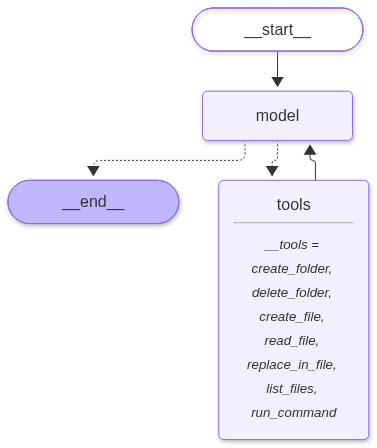

In [31]:
SYSTEM = """Jesteś agentem kodującym. Twoim zadaniem jest implementacja zadań programistycznych zleconych przez użytkownika.
Masz dostępne narzędzia do pracy z systemem plików (create_folder, delete_folder, list_files, create_file, read_file, replace_in_file) oraz wierszem poleceń (run_command).
Pracujesz wyłącznie w katalogu roboczym, wszystkie ścieżki podawaj jako relatywne do niego. Nie możesz czytać ani tworzyć plików poza tym katalogiem.

Zawsze stosuj poniższy iteracyjny cykl pracy:
1. Plan - zrozum zadanie, zaplanuj i zaproponuj kroki implementacji w pierwszej wiadomości.
2. Kodowanie - wykonaj wymagane zmiany w kodzie i/lub strukturze projektu.
3. Testowanie - sprawdż poprawność wykonia, testy powinny być odtwarzalne.
Podaj plan i przejdź do implementacji od razu w jednej odpowiedzi.
Powtarzaj te kroki dopóki nie zakończysz implementacji zadania z sukcesem.
WSZYSTKIE testy MUSZĄ przechodzić poprawnie - poprawiaj kod do skutku.
"""

from langchain_core.messages import SystemMessage
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.prebuilt import ToolNode, tools_condition
from IPython.display import Image, display

llm_with_tools = llm.bind_tools(TOOLS, parallel_tool_calls=True)

def call_model(state: MessagesState):

    reply = llm_with_tools.invoke([SystemMessage(SYSTEM)] + state["messages"])
    return {"messages": [reply]}

builder = StateGraph(MessagesState)
builder.add_node("model", call_model)
builder.add_node("tools", ToolNode(TOOLS))
builder.add_edge(START, "model")
builder.add_conditional_edges("model", tools_condition)
builder.add_edge("tools", "model")
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

## Część 3. Uruchomienie

Polecenie dla agenta jest podane poniżej. Można zmienić temat aplikacji (np. biblioteka zamiast sklepu), ale zakres musi zostać taki sam: jeden plik aplikacji, SQLite, kilka endpointów i testy.

1. Uruchomienie przez `graph.stream(..., stream_mode="updates", config={"recursion_limit": 60})` z wypisaniem każdego kroku: nazwa narzędzia, skrócone argumenty, skrócony wynik.
2. Na końcu: liczba wywołań modelu, liczba wywołań narzędzi i suma tokenów wejściowych (`usage_metadata` w odpowiedziach modelu).
3. Sprawdzenie wyniku **niezależnie od agenta**: lista plików, treść `app.py` i `test_app.py`, uruchomienie `pytest` z komórki notebooka.

In [20]:
import json

TASK = """Utwórz małą aplikację FastAPI: sklep internetowy.

- Cały kod aplikacji w jednym pliku app.py, baza SQLite w pliku shop.db.
- Przy starcie aplikacja tworzy tabelę products (id, name, price, stock), a gdy tabela jest pusta, dodaje 5 przykładowych produktów.
- Endpointy:
  - GET /products: lista produktów,
  - GET /products/{id}: jeden produkt, 404 gdy nie istnieje,
  - POST /products: dodanie produktu, zwraca 201,
  - POST /products/{id}/buy: zmniejsza stock o 1, 404 gdy produkt nie istnieje, 409 gdy stock wynosi 0.
- Testy w pliku test_app.py (pytest i TestClient z FastAPI) sprawdzają każdy endpoint, także błędy 404 i 409.
- Uruchom testy poleceniem `python -m pytest -q`. Jeśli nie przechodzą, popraw kod i uruchom je ponownie."""

model_calls = 0
tools_calls = 0
usage_history = []

for update in graph.stream(
    input={"messages": [("user", TASK)]},
    config={"recursion_limit": 60},
    stream_mode="updates",
  ):
    for node, change in update.items():
        if node == "model":
            model_calls += 1
        elif node == "tools":
            tools_calls += 1
        for m in change["messages"]:

            if node == "model":
                usage_history.append(m.usage_metadata)

            if m.type == "ai" and m.tool_calls:
                what = ", ".join(f"{c['name']}({json.dumps(c['args'], ensure_ascii=False)})" for c in m.tool_calls)
            else:
                what = m.content.strip().replace("\n", " ")
            print(f"{node:>5} -> {what}")

model -> create_file({"content": "\nimport sqlite3\nfrom fastapi import FastAPI, HTTPException, status\nfrom pydantic import BaseModel\nimport os\n\n# --- Konfiguracja ---\nDB_NAME = \"shop.db\"\napp = FastAPI()\n\n# --- Modele Danych ---\nclass ProductBase(BaseModel):\n    name: str\n    price: float\n    stock: int\n\nclass ProductCreate(ProductBase):\n    pass\n\nclass ProductInDB(ProductBase):\n    id: int\n\n    class Config:\n        orm_mode = True\n\n# --- Funkcje Bazy Danych ---\ndef get_db_connection():\n    conn = sqlite3.connect(DB_NAME)\n    conn.row_factory = sqlite3.Row\n    return conn\n\ndef initialize_db():\n    conn = get_db_connection()\n    cursor = conn.cursor()\n    \n    # 1. Tworzenie tabeli\n    cursor.execute(\"\"\"\n        CREATE TABLE IF NOT EXISTS products (\n            id INTEGER PRIMARY KEY AUTOINCREMENT,\n            name TEXT NOT NULL,\n            price REAL NOT NULL,\n            stock INTEGER NOT NULL\n        )\n    \"\"\")\n    conn.commit()\n\n

In [33]:
print(f"Liczba wywołań modelu: {model_calls}")
print(f"Liczba wywołań tools: {tools_calls}")
if usage_history:
    print(f"{'input_tokens':>12} {'output_tokens':>13} {'total_tokens':>12}")
    print(f"{'-' * 12} {'-' * 13} {'-' * 12}")
    for usage in usage_history:
        print(f"{usage.get('input_tokens', 0):>12} {usage.get('output_tokens', 0):>13} {usage.get('total_tokens', 0):>12}")
else:
    print("Brak danych usage_metadata")


Liczba wywołań modelu: 7
Liczba wywołań tools: 6
input_tokens output_tokens total_tokens
------------ ------------- ------------
        1001          2730         3731
        2889          1820         4709
        4479          2067         6546
        6366           386         6752
        8581           976         9557
        9107           438         9545
        9649           499        10148


In [34]:
print("Lista plików w WORKSPACE")
print(list_files.invoke({"path": "."}), end="\n\n")

print("Treść pliku app.py")
print(read_file.invoke({"path": "app.py"}), end="\n\n")

print("Treść pliku test_app.py")
print(read_file.invoke({"path": "test_app.py"}))

Lista plików w WORKSPACE
dir: .pytest_cache
file: .pytest_cache/.gitignore
file: .pytest_cache/CACHEDIR.TAG
file: .pytest_cache/README.md
dir: .pytest_cache/v
dir: .pytest_cache/v/cache
file: .pytest_cache/v/cache/lastfailed
file: .pytest_cache/v/cache/nodeids
dir: __pycache__
file: __pycache__/app.cpython-315.pyc
file: __pycache__/test_app.cpython-315-pytest-9.2.0.pyc
file: app.py
file: shop.db
file: test_app.py

Treść pliku app.py

import sqlite3
from fastapi import FastAPI, HTTPException, status
from pydantic import BaseModel
import os

# --- Konfiguracja ---
DB_NAME = "shop.db"
app = FastAPI(title="Internet Shop API")

# --- Modele Danych ---
class ProductBase(BaseModel):
    name: str
    price: float
    stock: int

class ProductCreate(ProductBase):
    pass

class ProductInDB(ProductBase):
    id: int

    # Metoda konwersji z surowych danych SQLite
    @staticmethod
    def from_sqlite(p: sqlite3.Row) -> 'ProductInDB':
        return ProductInDB(id=p['id'], name=p['name'], pric

In [35]:
print(run_command.invoke({"command": "python -m pytest -q"}))

kod wyjścia: 0
stdout:
.......                                                                  [100%]
=============================== warnings summary ===============================
../../.venv/lib/python3.15/site-packages/langsmith/_internal/_beta_decorator.py:92: 17 warnings
  /Users/mihawb/Documents/pjatk-mgr/TEG/2026Z-PJATK-TEG/.venv/lib/python3.15/site-packages/langsmith/_internal/_beta_decorator.py:92: DeprecationWarning: 'asyncio.iscoroutinefunction' is deprecated and slated for removal in Python 3.16; use inspect.iscoroutinefunction() instead
    if asyncio.iscoroutinefunction(func):

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
7 passed, 17 warnings in 0.11s

stderr:
/Users/mihawb/Documents/pjatk-mgr/TEG/2026Z-PJATK-TEG/.venv/lib/python3.15/site-packages/pytest_asyncio/plugin.py:306: PytestDeprecationWarning: The configuration option "asyncio_default_fixture_loop_scope" is unset.
The event loop scope for asynchronous fixtures will default to the fi